# Wheeler County daily Outlook distributions and high-index area

**First code cell:** date-wise box-and-whisker plots of Outlook index and category using every native pixel intersecting Wheeler County, Oregon (FIPS 41069). No spatial subsampling is used. Boxes show the 25th–75th percentiles, a median line, 1.5-IQR whiskers and outliers. These are unweighted pixel distributions; category codes are ordinal. NaN indices and category 0 (unavailable) are excluded from their respective boxes.

**Second code cell:** daily percentage of **total county area** with Outlook index **strictly > 0.7**. The denominator includes the full county polygon (land and inland water); unavailable area is reported separately and is not classified as low-index area. This differs from the demo's eligible-land percentage and ≥0.70 threshold.

Area is estimated from native pixel footprints inferred from neighboring geolocation centres, projected into CONUS Albers equal-area (EPSG:5070) and clipped to the county polygon. Boundary pixels contribute only their within-county area. Original index and category values are not resampled. The county boundary is bundled separately in `assets/boundaries/wheeler_county_41069.geojson`, extracted from the demo's Census TIGERweb BAS 2026 geography cache. No external drive or network connection is needed to run the notebook.

Boundary source: [U.S. Census TIGERweb State/County](https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/State_County/MapServer/19). This notebook uses whichever catalogued NetCDF files are present in `outlook/data/`, currently July 10–19, 2026.

Wheeler County (41069): 4,445.72 km²; 37,103 intersecting native pixels
19 available daily files: 2026-07-03–2026-07-21


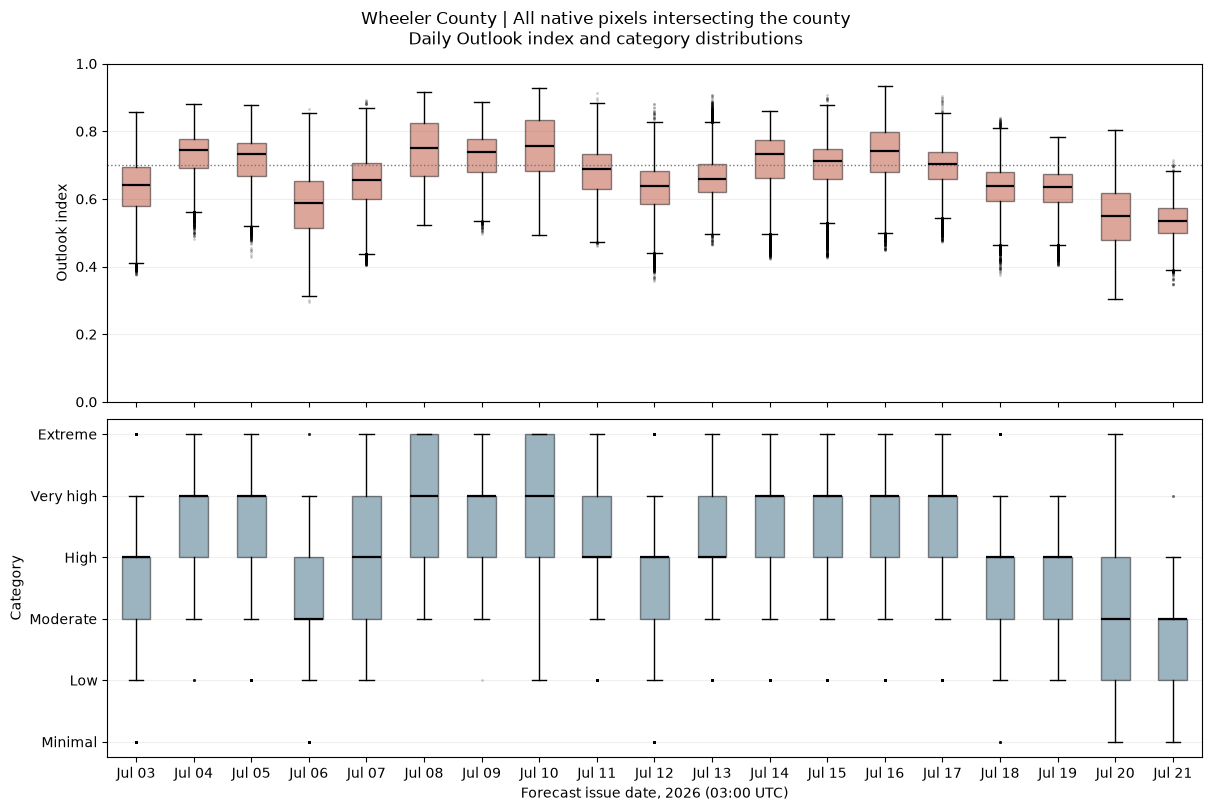

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapely
from shapely.geometry import shape
from shapely.ops import transform
from pyproj import Transformer
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'manifest.json').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'examples'))
import outlook

# Load the bundled Census BAS 2026 county boundary.
BOUNDARY_PATH = ROOT / 'assets/boundaries/wheeler_county_41069.geojson'
BOUNDARY = json.loads(BOUNDARY_PATH.read_text())
county = shape(BOUNDARY['features'][0]['geometry'])
project = Transformer.from_crs('EPSG:4326', 'EPSG:5070', always_xy=True)
county_m = transform(project.transform, county)
county_area_km2 = county_m.area / 1e6
assert county_m.is_valid
catalog = outlook.catalog().sort_values('date')
available = catalog.loc[catalog['file'].map(lambda name: (ROOT / name).is_file())]
assert len(available), 'Place the daily NetCDF files in outlook/data/.'

with outlook.open_day(available.iloc[0].date) as ds:
    lat, lon = ds.lat.values, ds.lon.values
    west, south, east, north = county.bounds
    # Bounding box locates a computational window only; county geometry selects pixels.
    candidate = (lon > west-.05) & (lon < east+.05) & (lat > south-.05) & (lat < north+.05)
    rr, cc = np.where(candidate)
    y0, y1 = max(0, rr.min()-2), min(lat.shape[0], rr.max()+3)
    x0, x1 = max(0, cc.min()-2), min(lat.shape[1], cc.max()+3)
    ys, xs = slice(y0, y1), slice(x0, x1)
    grid_lat, grid_lon = lat[ys, xs].copy(), lon[ys, xs].copy()
    del lat, lon, candidate, rr, cc

xx, yy = project.transform(grid_lon, grid_lat)
def corners(a):
    padded = np.pad(a, 1, mode='edge')
    padded[0, 1:-1] = 2*a[0] - a[1]
    padded[-1, 1:-1] = 2*a[-1] - a[-2]
    padded[:, 0] = 2*padded[:, 1] - padded[:, 2]
    padded[:, -1] = 2*padded[:, -2] - padded[:, -3]
    return (padded[:-1, :-1] + padded[1:, :-1] + padded[:-1, 1:] + padded[1:, 1:]) / 4
cx, cy = corners(xx), corners(yy)
vertices = np.stack([
    np.stack([cx[:-1, :-1], cy[:-1, :-1]], axis=-1),
    np.stack([cx[:-1, 1:], cy[:-1, 1:]], axis=-1),
    np.stack([cx[1:, 1:], cy[1:, 1:]], axis=-1),
    np.stack([cx[1:, :-1], cy[1:, :-1]], axis=-1)], axis=-2)
cells = shapely.polygons(vertices.reshape(-1, 4, 2))
overlap = shapely.intersects(cells, county_m)
area = np.zeros(len(cells))
area[overlap] = shapely.area(shapely.intersection(cells[overlap], county_m)) / 1e6
area = area.reshape(grid_lat.shape)
mask = area > 1e-9
weights = area[mask]
assert np.isclose(weights.sum(), county_area_km2, rtol=1e-5), 'Grid must cover the entire county.'
print(f'Wheeler County (41069): {county_area_km2:,.2f} km²; {mask.sum():,} intersecting native pixels')
print(f'{len(available)} available daily files: {available.iloc[0].date}–{available.iloc[-1].date}')

THRESHOLD = 0.7
index_samples, category_samples, records = [], [], []
for date in available.date:
    with outlook.open_day(date) as ds:
        np.testing.assert_array_equal(ds.lat[ys, xs].values, grid_lat)
        np.testing.assert_array_equal(ds.lon[ys, xs].values, grid_lon)
        values = ds.outlook_index[ys, xs].values[mask]
        categories = ds.category[ys, xs].values[mask]
        valid = np.isfinite(values)
        valid_category = (categories >= 1) & (categories <= 6)
        index_samples.append(values[valid])
        category_samples.append(categories[valid_category])
        # Compare in the source dtype so a stored float32 0.7 is excluded.
        high = valid & (values > np.asarray(THRESHOLD, dtype=values.dtype))
        high_km2 = weights[high].sum()
        valid_km2 = weights[valid].sum()
        records.append(dict(date=date, issue=pd.Timestamp(ds.attrs['forecast_issue_time']),
            valid_start=pd.Timestamp(ds.attrs['time_coverage_start']),
            valid_end=pd.Timestamp(ds.attrs['time_coverage_end']),
            county_area_km2=county_area_km2, valid_area_km2=valid_km2,
            valid_area_pct=100*valid_km2/county_area_km2,
            high_area_km2=high_km2, high_area_pct=100*high_km2/county_area_km2,
            missing_area_km2=county_area_km2-valid_km2,
            valid_index_pixels=int(valid.sum()), valid_category_pixels=int(valid_category.sum())))
daily = pd.DataFrame(records)
labels = [pd.Timestamp(d).strftime('%b %d') for d in daily.date]
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, layout='constrained')
for ax, samples, color in zip(axes, [index_samples, category_samples], ['#b53b22', '#245774']):
    bp = ax.boxplot(samples, patch_artist=True, whis=1.5, showfliers=True,
                    flierprops=dict(marker='.', markersize=2, alpha=.2),
                    medianprops=dict(color='black', linewidth=1.6))
    for box in bp['boxes']:
        box.set(facecolor=color, alpha=.45)
    ax.grid(axis='y', alpha=.2)
axes[0].set(ylabel='Outlook index', ylim=(0, 1))
axes[0].axhline(THRESHOLD, color='#777777', linestyle=':', linewidth=1)
axes[1].set_ylabel('Category')
axes[1].set_yticks(range(1, 7), outlook.CATEGORY_LABELS[1:])
axes[1].set_xticks(range(1, len(labels)+1), labels)
axes[1].set_xlabel('Forecast issue date, 2026 (03:00 UTC)')
fig.suptitle('Wheeler County | All native pixels intersecting the county\nDaily Outlook index and category distributions')
plt.show()


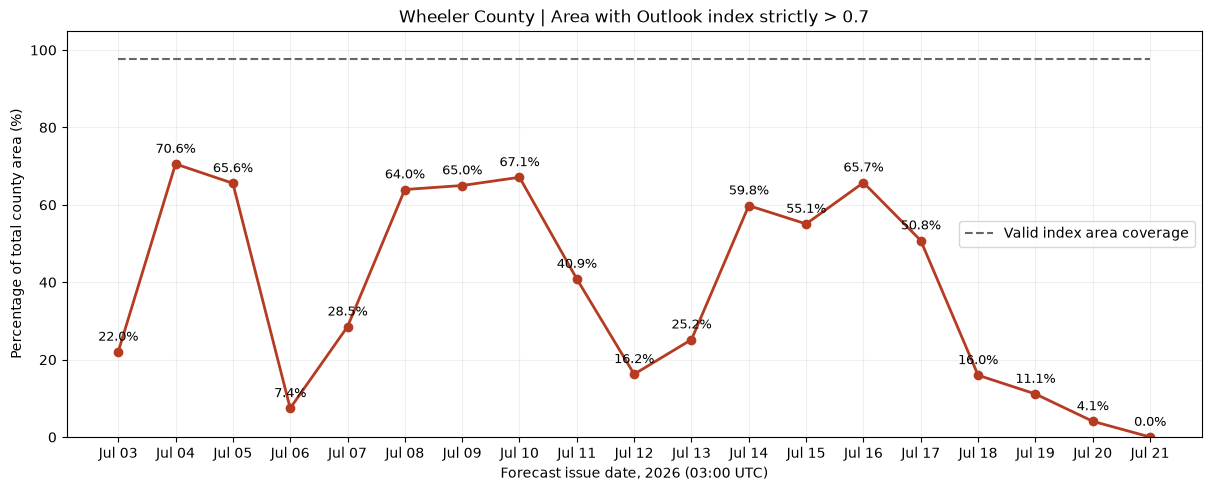

,date,high_area_pct,high_area_km2,county_area_km2,valid_area_pct,missing_area_km2,valid_index_pixels
0,2026-07-03,22.026,979.232,4445.717,97.762,99.477,36234
1,2026-07-04,70.564,3137.084,4445.717,97.762,99.477,36234
2,2026-07-05,65.567,2914.905,4445.717,97.762,99.477,36234
3,2026-07-06,7.445,331.003,4445.717,97.762,99.477,36234
4,2026-07-07,28.515,1267.681,4445.717,97.762,99.477,36234
5,2026-07-08,63.957,2843.340,4445.717,97.762,99.477,36234
6,2026-07-09,64.993,2889.407,4445.717,97.762,99.477,36234
7,2026-07-10,67.119,2983.903,4445.717,97.762,99.477,36234
8,2026-07-11,40.854,1816.245,4445.717,97.762,99.477,36234
9,2026-07-12,16.242,722.084,4445.717,97.762,99.477,36234


In [2]:
# Percentage of TOTAL Wheeler County area, strictly greater than 0.7.
# Partial boundary pixels contribute only their within-county area.
fig, ax = plt.subplots(figsize=(12, 4.8), layout='constrained')
dates = pd.to_datetime(daily.date)
regular_dates = pd.date_range(dates.min(), dates.max(), freq='D')
plotted = pd.Series(daily.high_area_pct.to_numpy(), index=dates).reindex(regular_dates)
ax.plot(plotted.index, plotted.values, color='#b53b22', marker='o', linewidth=2)
for date, value in zip(dates, daily.high_area_pct):
    ax.annotate(f'{value:.1f}%', (date, value), xytext=(0, 8),
                textcoords='offset points', ha='center', fontsize=9)
if (daily.valid_area_pct < 99.999).any():
    ax.plot(dates, daily.valid_area_pct, color='#666666', linestyle='--', label='Valid index area coverage')
    ax.legend()
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set(ylim=(0, 105), ylabel='Percentage of total county area (%)',
       xlabel='Forecast issue date, 2026 (03:00 UTC)',
       title='Wheeler County | Area with Outlook index strictly > 0.7')
ax.grid(alpha=.2)
plt.show()
display(daily[['date', 'high_area_pct', 'high_area_km2', 'county_area_km2',
               'valid_area_pct', 'missing_area_km2', 'valid_index_pixels']].round(3))


## Wheeler County maps for July 13–16

The third code cell plots the full native-resolution Outlook index in a 2×2 panel, clipped to Wheeler County. All four maps use the same 0–1 color scale and geographic extent. Gray inside the county indicates unavailable index values; white outside the boundary is not part of the county. Dates label the forecast issue at 03:00 UTC; validity is 12:00 UTC on that date to 12:00 UTC the following day.

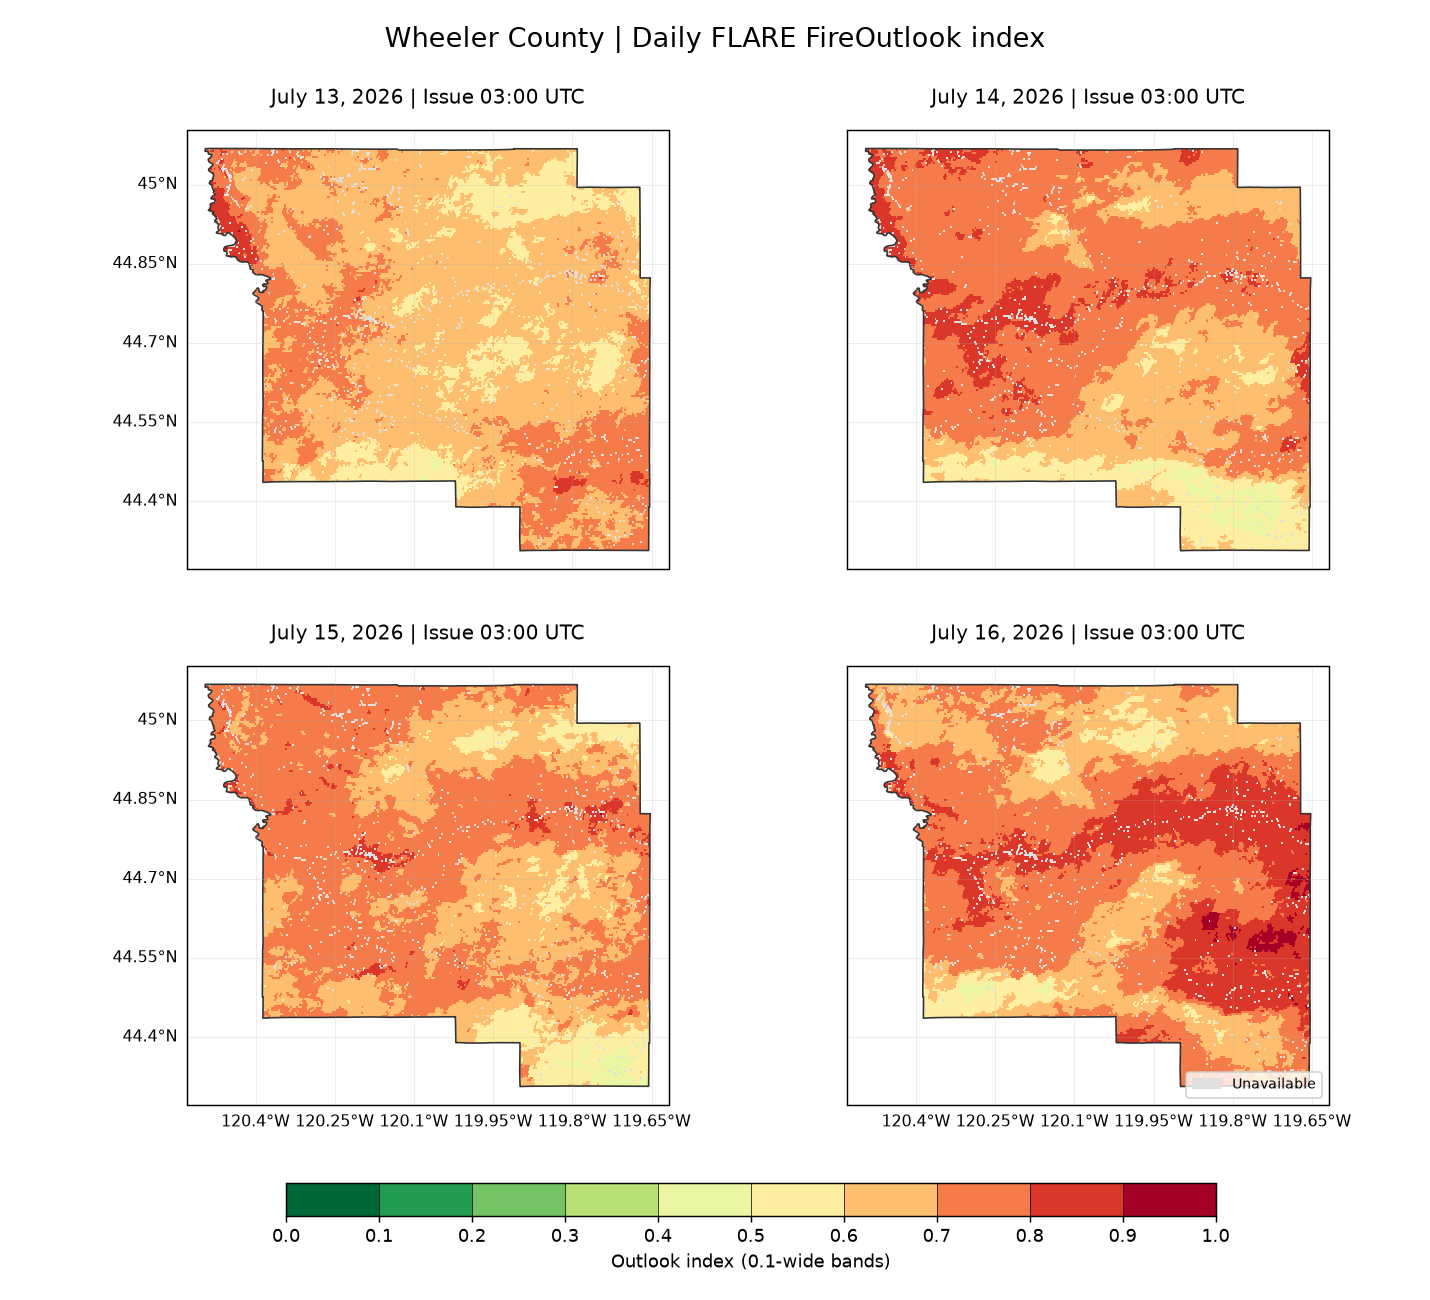

In [3]:
import cartopy.crs as ccrs
from matplotlib.path import Path as MplPath
from matplotlib.patches import PathPatch, Patch
from shapely.geometry.polygon import orient

MAP_DATES = ['2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16']
missing_dates = [date for date in MAP_DATES if date not in set(available.date)]
assert not missing_dates, f'Download these daily files into outlook/data/: {missing_dates}'

# The area-analysis cell constructed these native cell corners in EPSG:5070.
# Use the same footprints here, with geographic longitude/latitude labels.
geographic = ccrs.PlateCarree()
equal_area = ccrs.epsg(5070)
parts = [county] if county.geom_type == 'Polygon' else list(county.geoms)
rings = []
for polygon in parts:
    polygon = orient(polygon, sign=1.0)
    for ring in [polygon.exterior, *polygon.interiors]:
        coordinates = np.asarray(ring.coords)
        codes = np.full(len(coordinates), MplPath.LINETO, dtype=np.uint8)
        codes[0], codes[-1] = MplPath.MOVETO, MplPath.CLOSEPOLY
        rings.append(MplPath(coordinates, codes))
county_path = MplPath.make_compound_path(*rings)

fig, axes = plt.subplots(2, 2, figsize=(11, 10),
                         subplot_kw={'projection': geographic})
fig.subplots_adjust(left=.10, right=.96, bottom=.15, top=.90, wspace=.16, hspace=.22)
from matplotlib.colors import BoundaryNorm
bounds = np.linspace(0, 1, 11)
cmap = plt.get_cmap('RdYlGn_r', 10).copy()
cmap.set_bad('#e0e0e0')
norm = BoundaryNorm(bounds, cmap.N, clip=True)
extent = [west-.035, east+.035, south-.035, north+.035]
for i, (ax, date) in enumerate(zip(axes.flat, MAP_DATES)):
    with outlook.open_day(date) as ds:
        np.testing.assert_array_equal(ds.lat[ys, xs].values, grid_lat)
        np.testing.assert_array_equal(ds.lon[ys, xs].values, grid_lon)
        values = ds.outlook_index[ys, xs].values
    values = np.ma.masked_invalid(np.where(mask, values, np.nan))
    ax.set_facecolor('white')
    ax.set_extent(extent, crs=geographic)
    ax.add_geometries([county], crs=geographic, facecolor='#e0e0e0', edgecolor='none', zorder=0)
    mesh = ax.pcolormesh(cx, cy, values, transform=equal_area,
                         shading='flat', cmap=cmap, norm=norm, rasterized=True)
    # Clip edge pixels to the actual county outline, including any interior rings.
    mesh.set_clip_path(PathPatch(county_path, transform=ax.transData))
    ax.add_geometries([county], crs=geographic, facecolor='none',
                      edgecolor='#333333', linewidth=.9)
    grid = ax.gridlines(draw_labels=True, linewidth=.35, alpha=.35)
    grid.top_labels = grid.right_labels = False
    grid.left_labels = (i % 2 == 0)
    grid.bottom_labels = (i >= 2)
    grid.xlabel_style = grid.ylabel_style = {'size': 9}
    ax.text(.5, 1.06, pd.Timestamp(date).strftime('%B %d, %Y') + ' | Issue 03:00 UTC', transform=ax.transAxes, ha='center', fontsize=11)
colorbar_ax = fig.add_axes([.20, .065, .65, .025])
fig.colorbar(mesh, cax=colorbar_ax, orientation='horizontal',
             label='Outlook index (0.1-wide bands)', boundaries=bounds, ticks=bounds, drawedges=True)
axes[1, 1].legend(handles=[Patch(facecolor='#e0e0e0', label='Unavailable')],
                   loc='lower right', fontsize=8)
fig.suptitle('Wheeler County | Daily FLARE FireOutlook index', fontsize=15)
# Preserve the full canvas; automatic tight cropping can clip projected artists.
from io import BytesIO
from IPython.display import Image
buffer = BytesIO()
with plt.rc_context({'savefig.bbox': None}):
    fig.savefig(buffer, format='png', dpi=130, bbox_inches=None)
plt.close(fig)
display(Image(data=buffer.getvalue()))


## Categorical Outlook maps for July 13–16

The stored `category` values are plotted directly, not recalculated from the index or its 0.1 color bands. The six available classes use discrete green-to-red colors: **Minimal, Low, Moderate, High, Very high, Extreme**. Category 0 is shown in gray as unavailable; areas outside Wheeler County remain white. The dates, geographic extent and county clipping match the index panels above.

Stored category boundaries: 0, 0.40, 0.50, 0.60, 0.70, 0.80, 1. Lower bounds are included; upper bounds are excluded except 1 in Extreme. The original files are backed up.

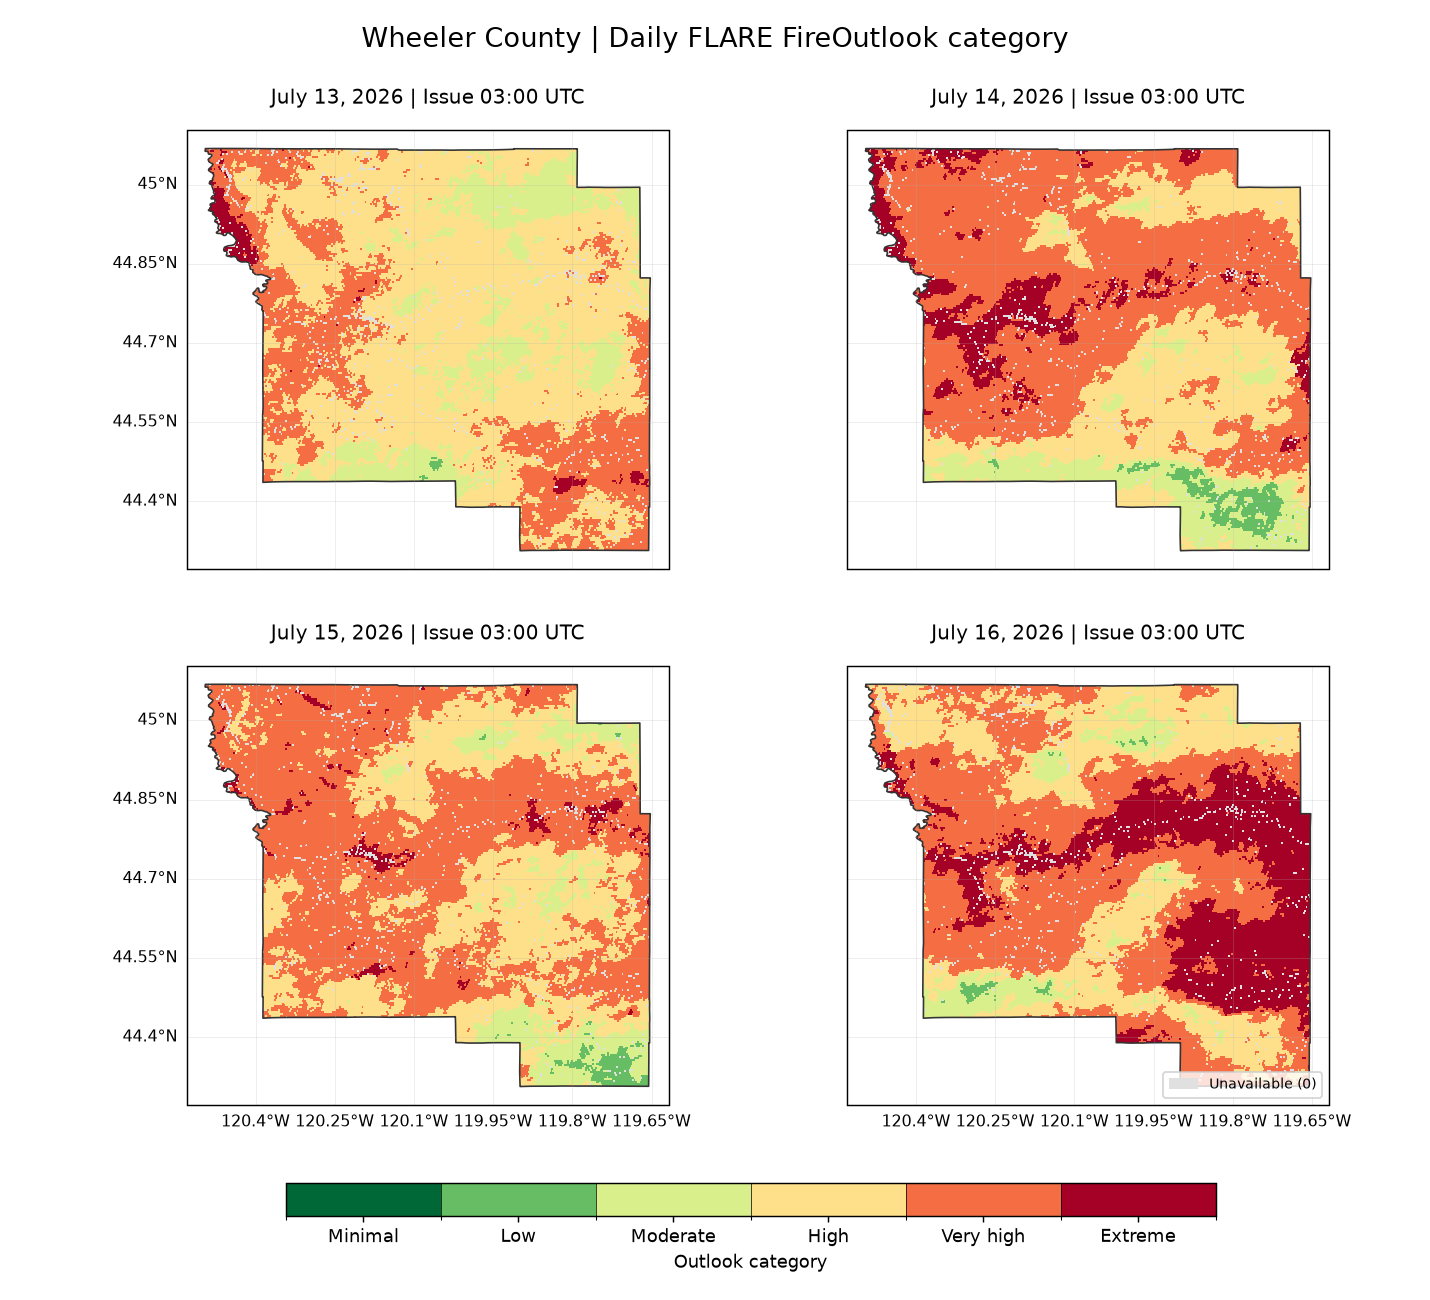

In [4]:
import cartopy.crs as ccrs

from matplotlib.path import Path as MplPath
from matplotlib.patches import PathPatch, Patch
from shapely.geometry.polygon import orient

MAP_DATES = ['2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16']
missing_dates = [date for date in MAP_DATES if date not in set(available.date)]
assert not missing_dates, f'Download these daily files into outlook/data/: {missing_dates}'

# The area-analysis cell constructed these native cell corners in EPSG:5070.
# Use the same footprints here, with geographic longitude/latitude labels.
geographic = ccrs.PlateCarree()
equal_area = ccrs.epsg(5070)
parts = [county] if county.geom_type == 'Polygon' else list(county.geoms)
rings = []
for polygon in parts:
    polygon = orient(polygon, sign=1.0)
    for ring in [polygon.exterior, *polygon.interiors]:
        coordinates = np.asarray(ring.coords)
        codes = np.full(len(coordinates), MplPath.LINETO, dtype=np.uint8)
        codes[0], codes[-1] = MplPath.MOVETO, MplPath.CLOSEPOLY
        rings.append(MplPath(coordinates, codes))
county_path = MplPath.make_compound_path(*rings)

fig, axes = plt.subplots(2, 2, figsize=(11, 10),
                         subplot_kw={'projection': geographic})
fig.subplots_adjust(left=.10, right=.96, bottom=.15, top=.90, wspace=.16, hspace=.22)
from matplotlib.colors import BoundaryNorm
bounds = np.arange(.5, 7, 1)
cmap = plt.get_cmap('RdYlGn_r', 6).copy()
cmap.set_bad('#e0e0e0')
norm = BoundaryNorm(bounds, cmap.N, clip=True)
extent = [west-.035, east+.035, south-.035, north+.035]
for i, (ax, date) in enumerate(zip(axes.flat, MAP_DATES)):
    with outlook.open_day(date) as ds:
        np.testing.assert_array_equal(ds.lat[ys, xs].values, grid_lat)
        np.testing.assert_array_equal(ds.lon[ys, xs].values, grid_lon)
        values = ds.category[ys, xs].values
    values = np.ma.masked_invalid(np.where(mask & (values >= 1) & (values <= 6), values, np.nan))
    ax.set_facecolor('white')
    ax.set_extent(extent, crs=geographic)
    ax.add_geometries([county], crs=geographic, facecolor='#e0e0e0', edgecolor='none', zorder=0)
    mesh = ax.pcolormesh(cx, cy, values, transform=equal_area,
                         shading='flat', cmap=cmap, norm=norm, rasterized=True)
    # Clip edge pixels to the actual county outline, including any interior rings.
    mesh.set_clip_path(PathPatch(county_path, transform=ax.transData))
    ax.add_geometries([county], crs=geographic, facecolor='none',
                      edgecolor='#333333', linewidth=.9)
    grid = ax.gridlines(draw_labels=True, linewidth=.35, alpha=.35)
    grid.top_labels = grid.right_labels = False
    grid.left_labels = (i % 2 == 0)
    grid.bottom_labels = (i >= 2)
    grid.xlabel_style = grid.ylabel_style = {'size': 9}
    ax.text(.5, 1.06, pd.Timestamp(date).strftime('%B %d, %Y') + ' | Issue 03:00 UTC', transform=ax.transAxes, ha='center', fontsize=11)
colorbar_ax = fig.add_axes([.20, .065, .65, .025])
cb = fig.colorbar(mesh, cax=colorbar_ax, orientation='horizontal',
                  label='Outlook category', boundaries=bounds, ticks=np.arange(1, 7), drawedges=True)
cb.set_ticklabels(outlook.CATEGORY_LABELS[1:])
axes[1, 1].legend(handles=[Patch(facecolor='#e0e0e0', label='Unavailable (0)')],
                   loc='lower right', fontsize=8)
fig.suptitle('Wheeler County | Daily FLARE FireOutlook category', fontsize=15)
# Preserve the full canvas; automatic tight cropping can clip projected artists.
from io import BytesIO
from IPython.display import Image
buffer = BytesIO()
with plt.rc_context({'savefig.bbox': None}):
    fig.savefig(buffer, format='png', dpi=130, bbox_inches=None)
plt.close(fig)
display(Image(data=buffer.getvalue()))


## NOAA/SPC Day 1 Fire Weather Outlook — July 13–16

Archived afternoon outlooks are shown in their **original SPC categories**, separately from FLARE's index and categories. Wind/relative-humidity categories and dry-thunderstorm areas are different hazards. Gray means **outside delineated SPC areas**, not a Low fire-danger rating. Each panel lists its UTC valid period; these afternoon issuances are not synchronized with FLARE's 03:00 UTC issue time.

Original polygon points and source URLs are cached in `outlook/assets/fire_comparisons/`, so rerunning requires no web requests. Source: [NOAA/SPC archive](https://www.spc.noaa.gov/products/fire_wx/2026/260713.html).

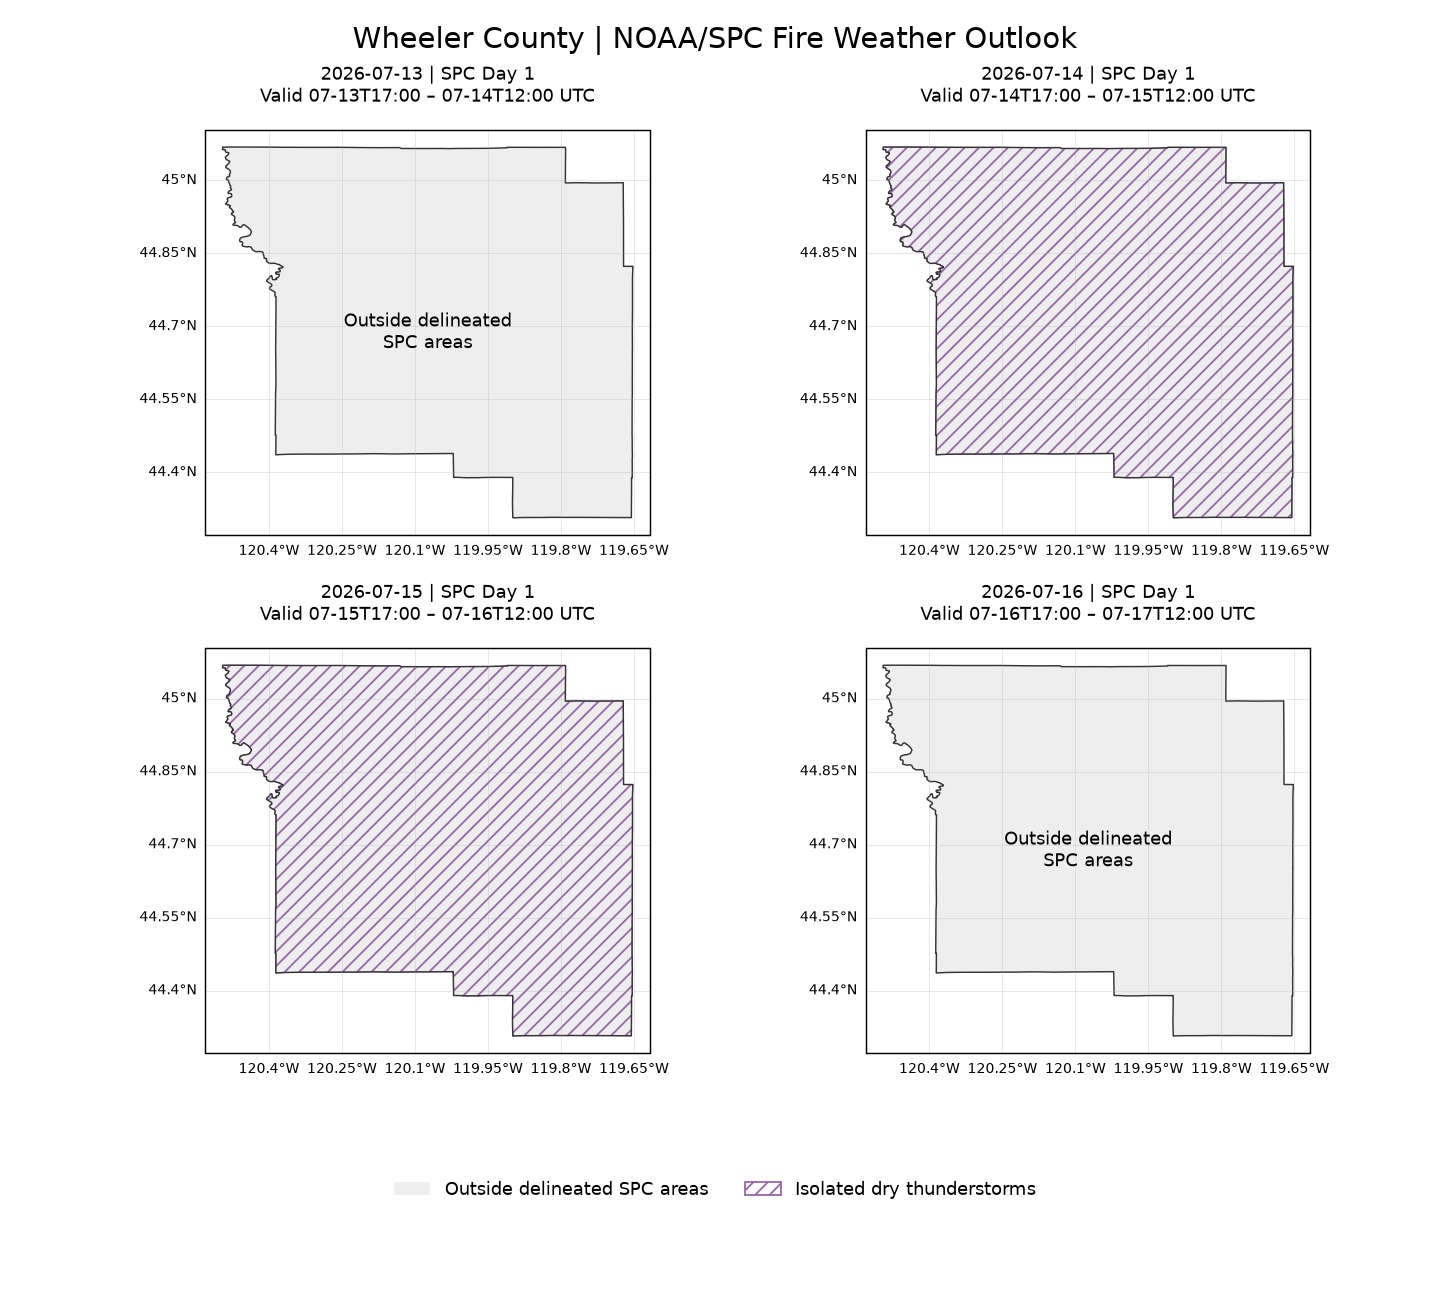

,date,SPC category,county area (%)
0,2026-07-13,Outside delineated SPC areas,100.0
1,2026-07-14,Isolated dry thunderstorms,100.0
2,2026-07-15,Isolated dry thunderstorms,100.0
3,2026-07-16,Outside delineated SPC areas,100.0


In [5]:
from matplotlib.patches import Patch
from shapely.ops import unary_union
from io import BytesIO
from IPython.display import Image

comparison_dir = ROOT / 'assets/fire_comparisons'
spc_style = {
    'ELEV': ('Elevated (wind/RH)', '#f4d35e', None),
    'CRIT': ('Critical (wind/RH)', '#ed6a3e', None),
    'EXTM': ('Extremely critical (wind/RH)', '#bc2464', None),
    'IDRT': ('Isolated dry thunderstorms', '#9966aa', '///'),
    'SDRT': ('Scattered dry thunderstorms', '#673287', 'xxx'),
}
fig, axes = plt.subplots(2, 2, figsize=(11, 10), subplot_kw={'projection': geographic})
fig.subplots_adjust(left=.10, right=.96, bottom=.19, top=.90, wspace=.16, hspace=.28)
coverage_rows = []
present = set()
for ax, day in zip(axes.flat, MAP_DATES):
    record = json.loads((comparison_dir / f'spc_{day}.geojson').read_text())
    ax.set_extent(extent, crs=geographic)
    ax.add_geometries([county], geographic, facecolor='#eeeeee', edgecolor='none')
    grouped = {}
    for feature in record['features']:
        code = feature['properties']['category']
        assert code in spc_style, f'Unknown SPC category: {code}'
        clipped = shape(feature['geometry']).intersection(county)
        if not clipped.is_empty and clipped.area > 0:
            grouped.setdefault(code, []).append(clipped)
    for code in spc_style:
        if code not in grouped:
            continue
        geometry = unary_union(grouped[code])
        label, color, hatch = spc_style[code]
        present.add(code)
        ax.add_geometries([geometry], geographic, facecolor=color if hatch is None else 'none',
                          edgecolor=color, hatch=hatch, linewidth=.5)
        percent = transform(project.transform, geometry).area / county_m.area * 100
        coverage_rows.append({'date': day, 'SPC category': label, 'county area (%)': round(percent, 2)})
    if not grouped:
        ax.text(.5, .5, 'Outside delineated\nSPC areas', transform=ax.transAxes,
                ha='center', va='center', fontsize=10)
        coverage_rows.append({'date': day, 'SPC category': 'Outside delineated SPC areas', 'county area (%)': 100.0})
    ax.add_geometries([county], geographic, facecolor='none', edgecolor='#333333', linewidth=.8)
    grid = ax.gridlines(draw_labels=True, linewidth=.4, alpha=.4)
    grid.top_labels = False
    grid.right_labels = False
    grid.xlabel_style = {'size': 8}
    grid.ylabel_style = {'size': 8}
    start, end = record['valid_start'], record['valid_end']
    ax.text(.5, 1.07, f'{day} | SPC Day 1\nValid {start[5:16]} – {end[5:16]} UTC',
            transform=ax.transAxes, ha='center', fontsize=10)
handles = [Patch(facecolor='#eeeeee', label='Outside delineated SPC areas')]
for code in spc_style:
    if code in present:
        label, color, hatch = spc_style[code]
        handles.append(Patch(facecolor=color if hatch is None else 'white', edgecolor=color, hatch=hatch, label=label))
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.5, .065), ncol=2, frameon=False)
fig.suptitle('Wheeler County | NOAA/SPC Fire Weather Outlook', fontsize=16, y=.98)
buffer = BytesIO()
with plt.rc_context({'savefig.bbox': None}):
    fig.savefig(buffer, format='png', dpi=130, bbox_inches=None)
plt.close(fig)
display(Image(data=buffer.getvalue()))
display(pd.DataFrame(coverage_rows))


## Numerical fire-danger comparisons: definitions and interpretation

These USGS **Day 1 forecasts** cover July 13–16, 2026. The columns retain their native grids and original units.

### WFPI — Wildland Fire Potential Index

A unitless indicator of vegetation flammability, incorporating fuel condition and weather. Higher values indicate conditions more supportive of large fires. The panel uses a fixed **0–150** color scale. **WFPI 80 is an index value, not an 80% probability.** [USGS WFPI definition](https://www.usgs.gov/fire-danger-forecast/wildland-fire-potential-index-wfpi)

### SP — Fire Spread Probability (WFSP in the panel)

The estimated probability that an **existing one-acre fire** grows to exceed **500 acres**. Units are **percent**. For example, a value of **15** means a modeled **15% chance of that growth, conditional on an existing one-acre fire**. It is neither spread speed nor the probability of ignition. [USGS WFSP definition](https://www.usgs.gov/fire-danger-forecast/wfpi-based-fire-spread-probability-wfsp)

### FP — Large Fire Probability (WLFP in the panel)

The estimated probability of a new fire occurring that ultimately exceeds **500 acres**, expressed here **per million pixel-days** (USGS defines the reference voxel as a km²-day). A displayed value of **3** corresponds to **3 per million**, or **0.0003% per reference pixel-day**—not 3%, and not three fires expected in Wheeler County. Unlike SP, this is not conditioned on a fire already existing. [USGS WLFP definition](https://www.usgs.gov/fire-danger-forecast/wfpi-based-large-fire-probability-wlfp)

### Reading the comparison

- Read each column using its own colorbar. Equal colors across different products do not represent equal probabilities.
- Color limits stay fixed across the four dates within each column.
- Median pixel area beneath each heading is the median full native-cell footprint among valid county-intersecting cells on the first displayed date, measured in an equal-area projection; it is not the area burned.
- Gray represents unavailable values or excluded USGS land/status codes, not zero danger. Native cells are retained without interpolation onto the FLARE grid.
- The archive verifies each product's valid date, but does not provide an exact issuance timestamp or hourly lead. Matching row dates does not establish identical issuance times or daily valid windows.

Numerical subsets and source metadata are included locally, so the notebook runs offline. USGS special codes 249–254 (WFPI/WFSP) and 2490–2540 in steps of 10 (WLFP) are excluded from numerical statistics. The following table reports coverage and area-weighted county means.


In [6]:
import fire_comparisons as fc
comparison_county, numerical_data, numerical_summary = fc.load(ROOT)
display(numerical_summary[['product', 'date', 'units', 'native_pixels', 'valid_county_area_pct', 'special_code_area_pct', 'area_weighted_mean']].round(3))
display(numerical_summary[['product', 'valid_date', 'issue_time', 'lead_hours', 'timing_note']])


,product,date,units,native_pixels,valid_county_area_pct,special_code_area_pct,area_weighted_mean
0,wfpi,2026-07-13,unitless index,4623,99.957,0.043,64.667
1,wfpi,2026-07-14,unitless index,4623,99.957,0.043,62.340
2,wfpi,2026-07-15,unitless index,4623,99.957,0.043,60.002
3,wfpi,2026-07-16,unitless index,4623,99.957,0.043,60.975
4,wfsp,2026-07-13,percent,4623,99.957,0.043,13.013
5,wfsp,2026-07-14,percent,4623,99.957,0.043,12.863
6,wfsp,2026-07-15,percent,4623,99.957,0.043,12.600
7,wfsp,2026-07-16,percent,4623,99.957,0.043,12.929
8,wlfp,2026-07-13,per million pixel-days,4623,99.957,0.043,2.250
9,wlfp,2026-07-14,per million pixel-days,4623,99.957,0.043,2.129


,product,valid_date,issue_time,lead_hours,timing_note
0,wfpi,2026-07-13,None,None,Day 1 archive and ground-condition date verifi...
1,wfpi,2026-07-14,None,None,Day 1 archive and ground-condition date verifi...
2,wfpi,2026-07-15,None,None,Day 1 archive and ground-condition date verifi...
3,wfpi,2026-07-16,None,None,Day 1 archive and ground-condition date verifi...
4,wfsp,2026-07-13,None,None,Day 1 archive and ground-condition date verifi...
5,wfsp,2026-07-14,None,None,Day 1 archive and ground-condition date verifi...
6,wfsp,2026-07-15,None,None,Day 1 archive and ground-condition date verifi...
7,wfsp,2026-07-16,None,None,Day 1 archive and ground-condition date verifi...
8,wlfp,2026-07-13,None,None,Day 1 archive and ground-condition date verifi...
9,wlfp,2026-07-14,None,None,Day 1 archive and ground-condition date verifi...


## Date-by-product comparison — actual scales

Rows are July 13–16; columns are FLARE FireOutlook index, FLARE category, USGS WFPI, WFSP and WLFP. All columns use green-to-red colors with a fixed original-unit scale across the four dates. FLARE index uses the full **0–1** scale. FLARE FireOutlook categories use the revised stored NetCDF values; unavailable pixels remain gray. WFPI uses a fixed 0–150 scale; WFSP and WLFP scales are unchanged.

No data normalization is applied. Equal colors across products do not imply equal probabilities. USGS columns are Day-1 forecasts, not observations. Rows use the product's labeled daily date; identical issuance times and daily valid windows are not implied.

Every panel includes the same early Crosswhite footprint from [NIFC WFIGS Daily Perimeters](https://www.arcgis.com/home/item.html?id=7fa2437e625d49f7af1017c8617b68c1), object 58164 (BurnPeriod 2), perimeter timestamp July 16, 2026 at 16:25 UTC. The outline is dashed on July 13–15 as a subsequent fire footprint, and solid on July 16. Discovery was July 16 at 00:51:54 UTC (July 15 at 5:51:54 p.m. PDT); this styling follows UTC calendar dates, not local calendar dates. The fixed outline is retrospective context, not a daily growth sequence or an assertion that this perimeter was available at forecast issuance. Geometry and source attributes are stored separately in `assets/fire_comparisons/crosswhite_early_perimeter.geojson`.

The category column reads the revised stored NetCDF category, defined from the index using boundaries 0, 0.40, 0.50, 0.60, 0.70, 0.80, 1. Intervals include their lower bound and exclude the upper bound, except the last includes 1. The six labels are Minimal, Low, Moderate, High, Very high and Extreme. The NetCDF category values and metadata have been updated to these boundaries; the original files are backed up. Index and coordinate values are unchanged.

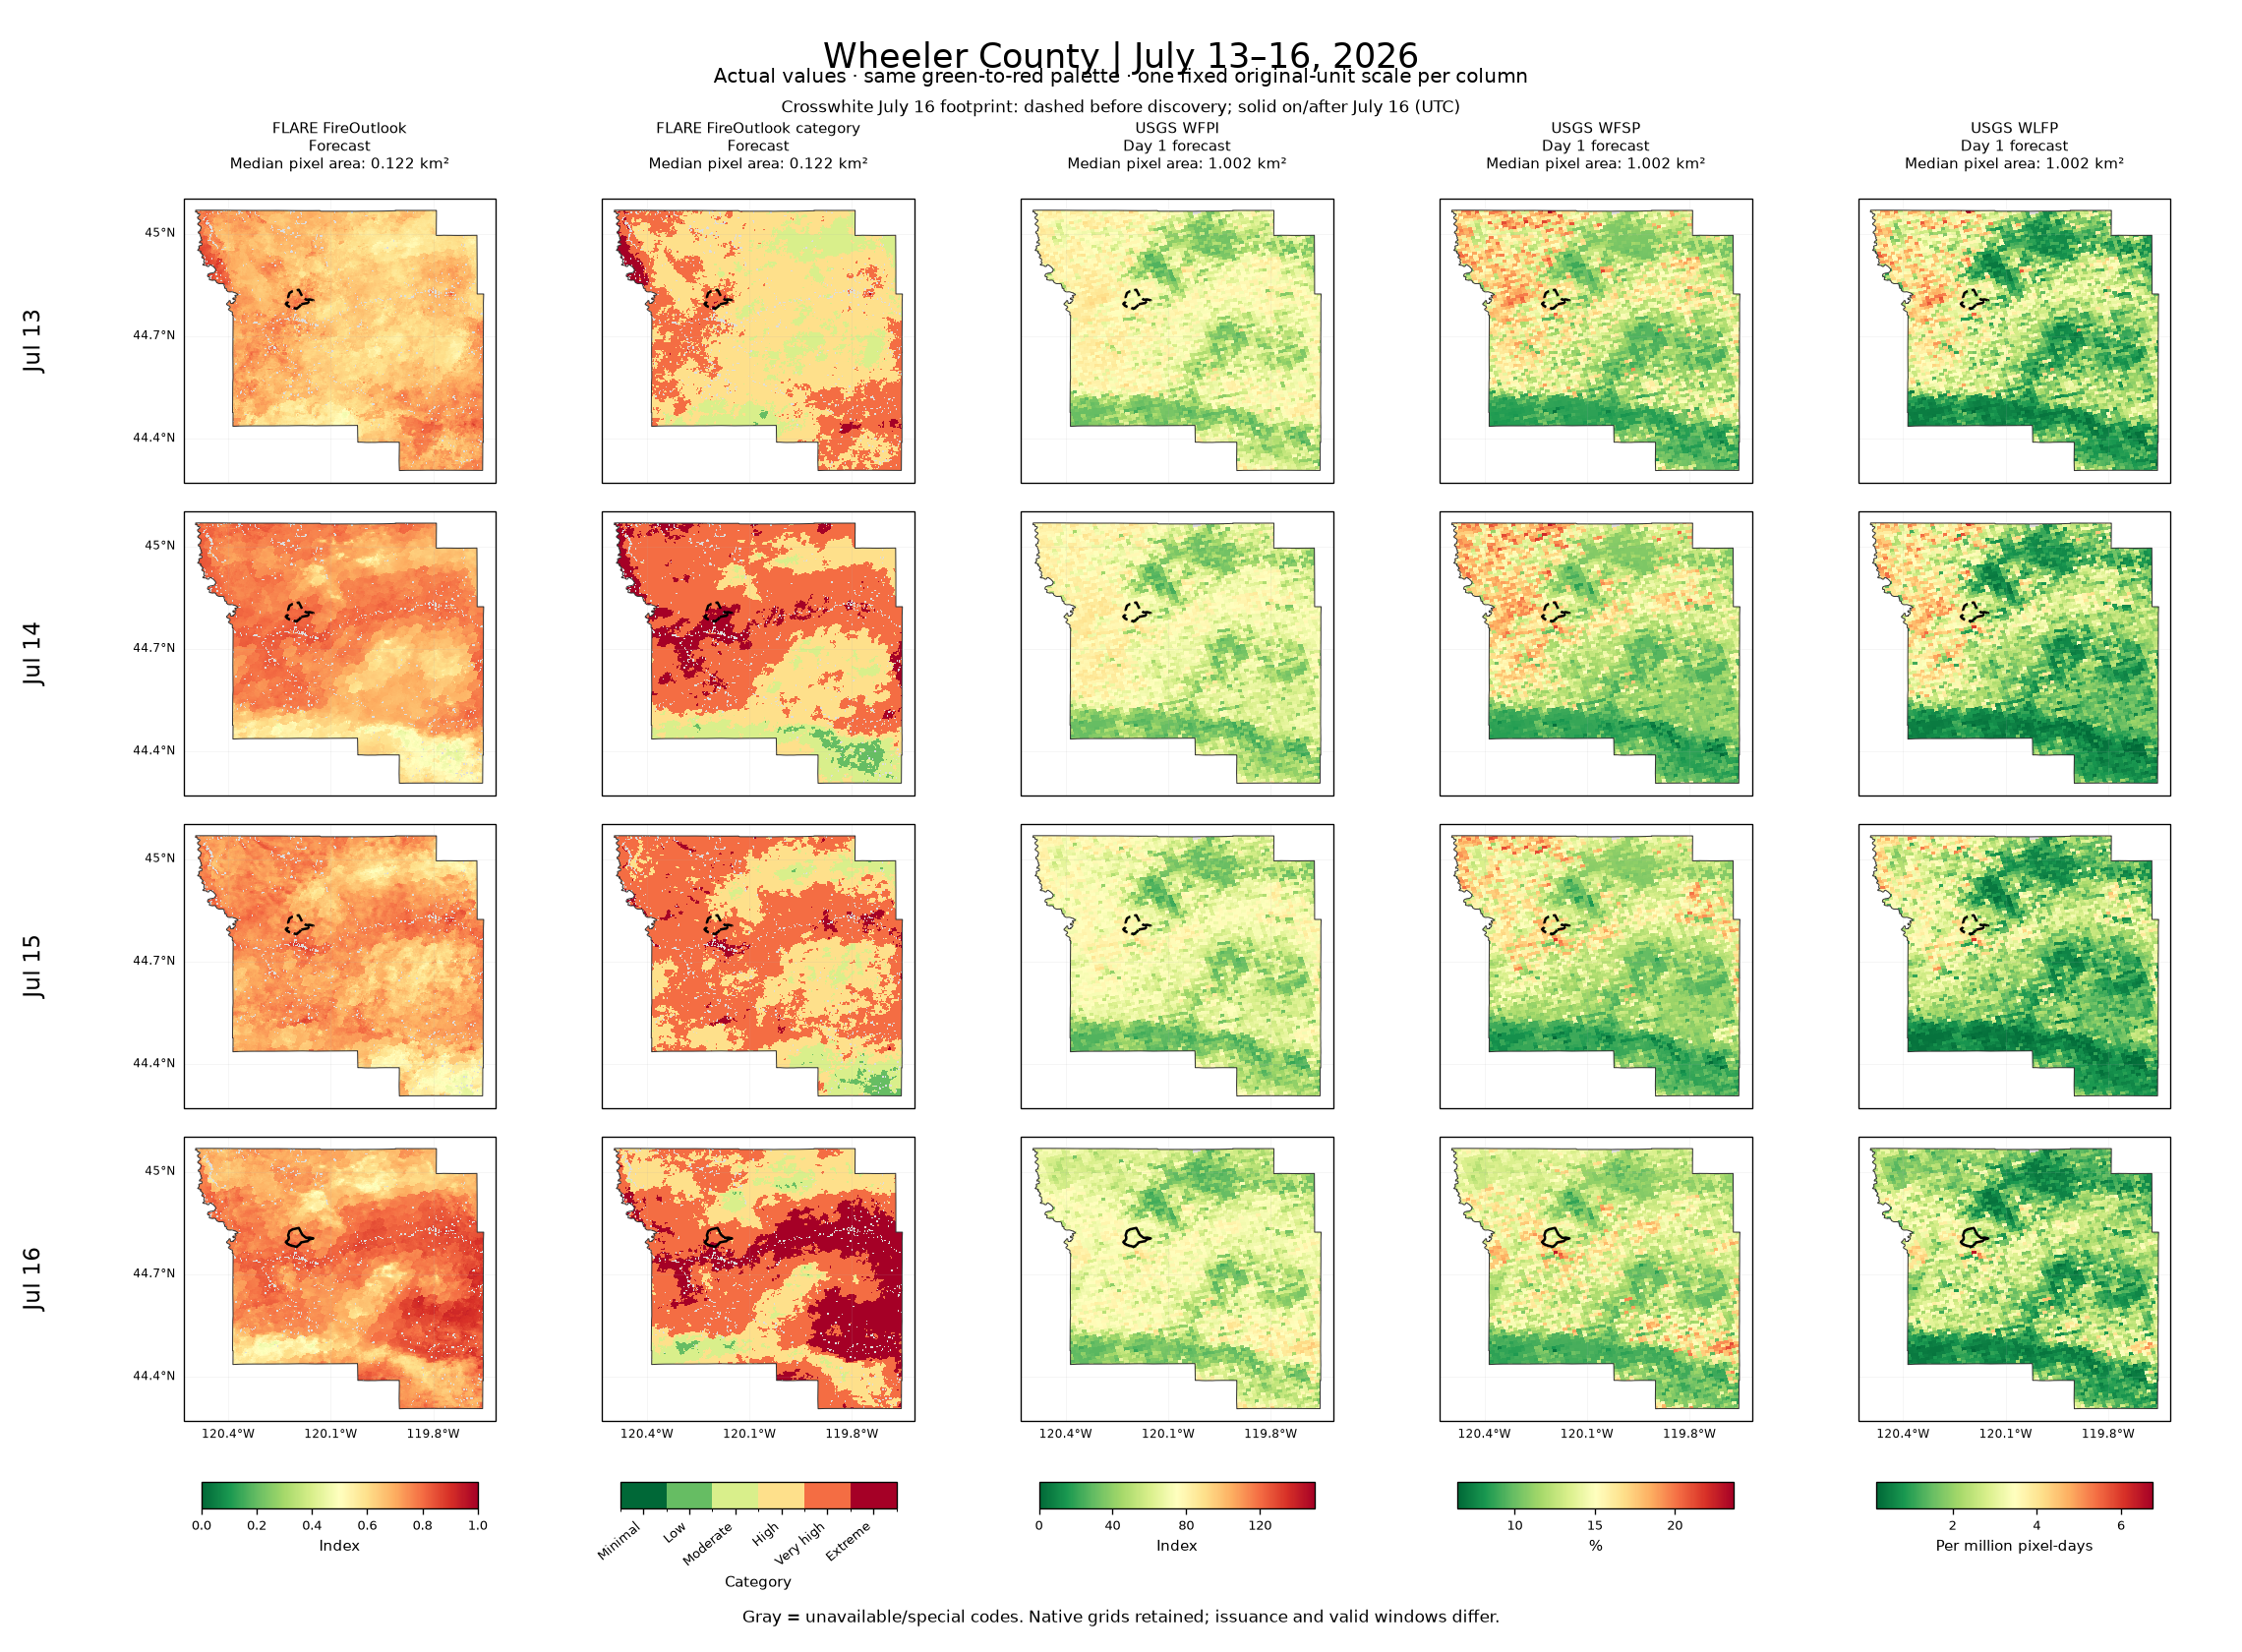

In [7]:
# Preserve FLARE's native cells; convert only cell-corner coordinates for plotting.
to_lonlat = Transformer.from_crs('EPSG:5070', 'EPSG:4326', always_xy=True)
flare_lon_edges, flare_lat_edges = to_lonlat.transform(cx, cy)
flare_matrix = []
for day in fc.DATES:
    with outlook.open_day(day) as ds:
        values = ds.outlook_index[ys, xs].values.copy()
        categories = ds.category[ys, xs].values.copy()
    valid = mask & np.isfinite(values)
    flare_matrix.append(dict(values=values, valid=valid, samples=values[valid], categories=categories, county_mask=mask,
                             lon=flare_lon_edges, lat=flare_lat_edges))
fc.matrix(comparison_county, numerical_data, flare_matrix)


## Wider comparison with NIFC reported origin

Map limits are exactly the minimum and maximum longitude/latitude of the early July 16 Crosswhite perimeter (not the county or final fire extent). A crosshair marks the NIFC reported origin at 44.803333° N, 120.199167° W. Dashed outlines precede discovery by UTC date; July 16 is solid. Native cells and existing fixed color scales are retained. The county comparison above remains available.

The category column reads the revised stored NetCDF category, defined from the index using boundaries 0, 0.40, 0.50, 0.60, 0.70, 0.80, 1. Intervals include their lower bound and exclude the upper bound, except the last includes 1. The six labels are Minimal, Low, Moderate, High, Very high and Extreme. The NetCDF category values and metadata have been updated to these boundaries; the original files are backed up. Index and coordinate values are unchanged.

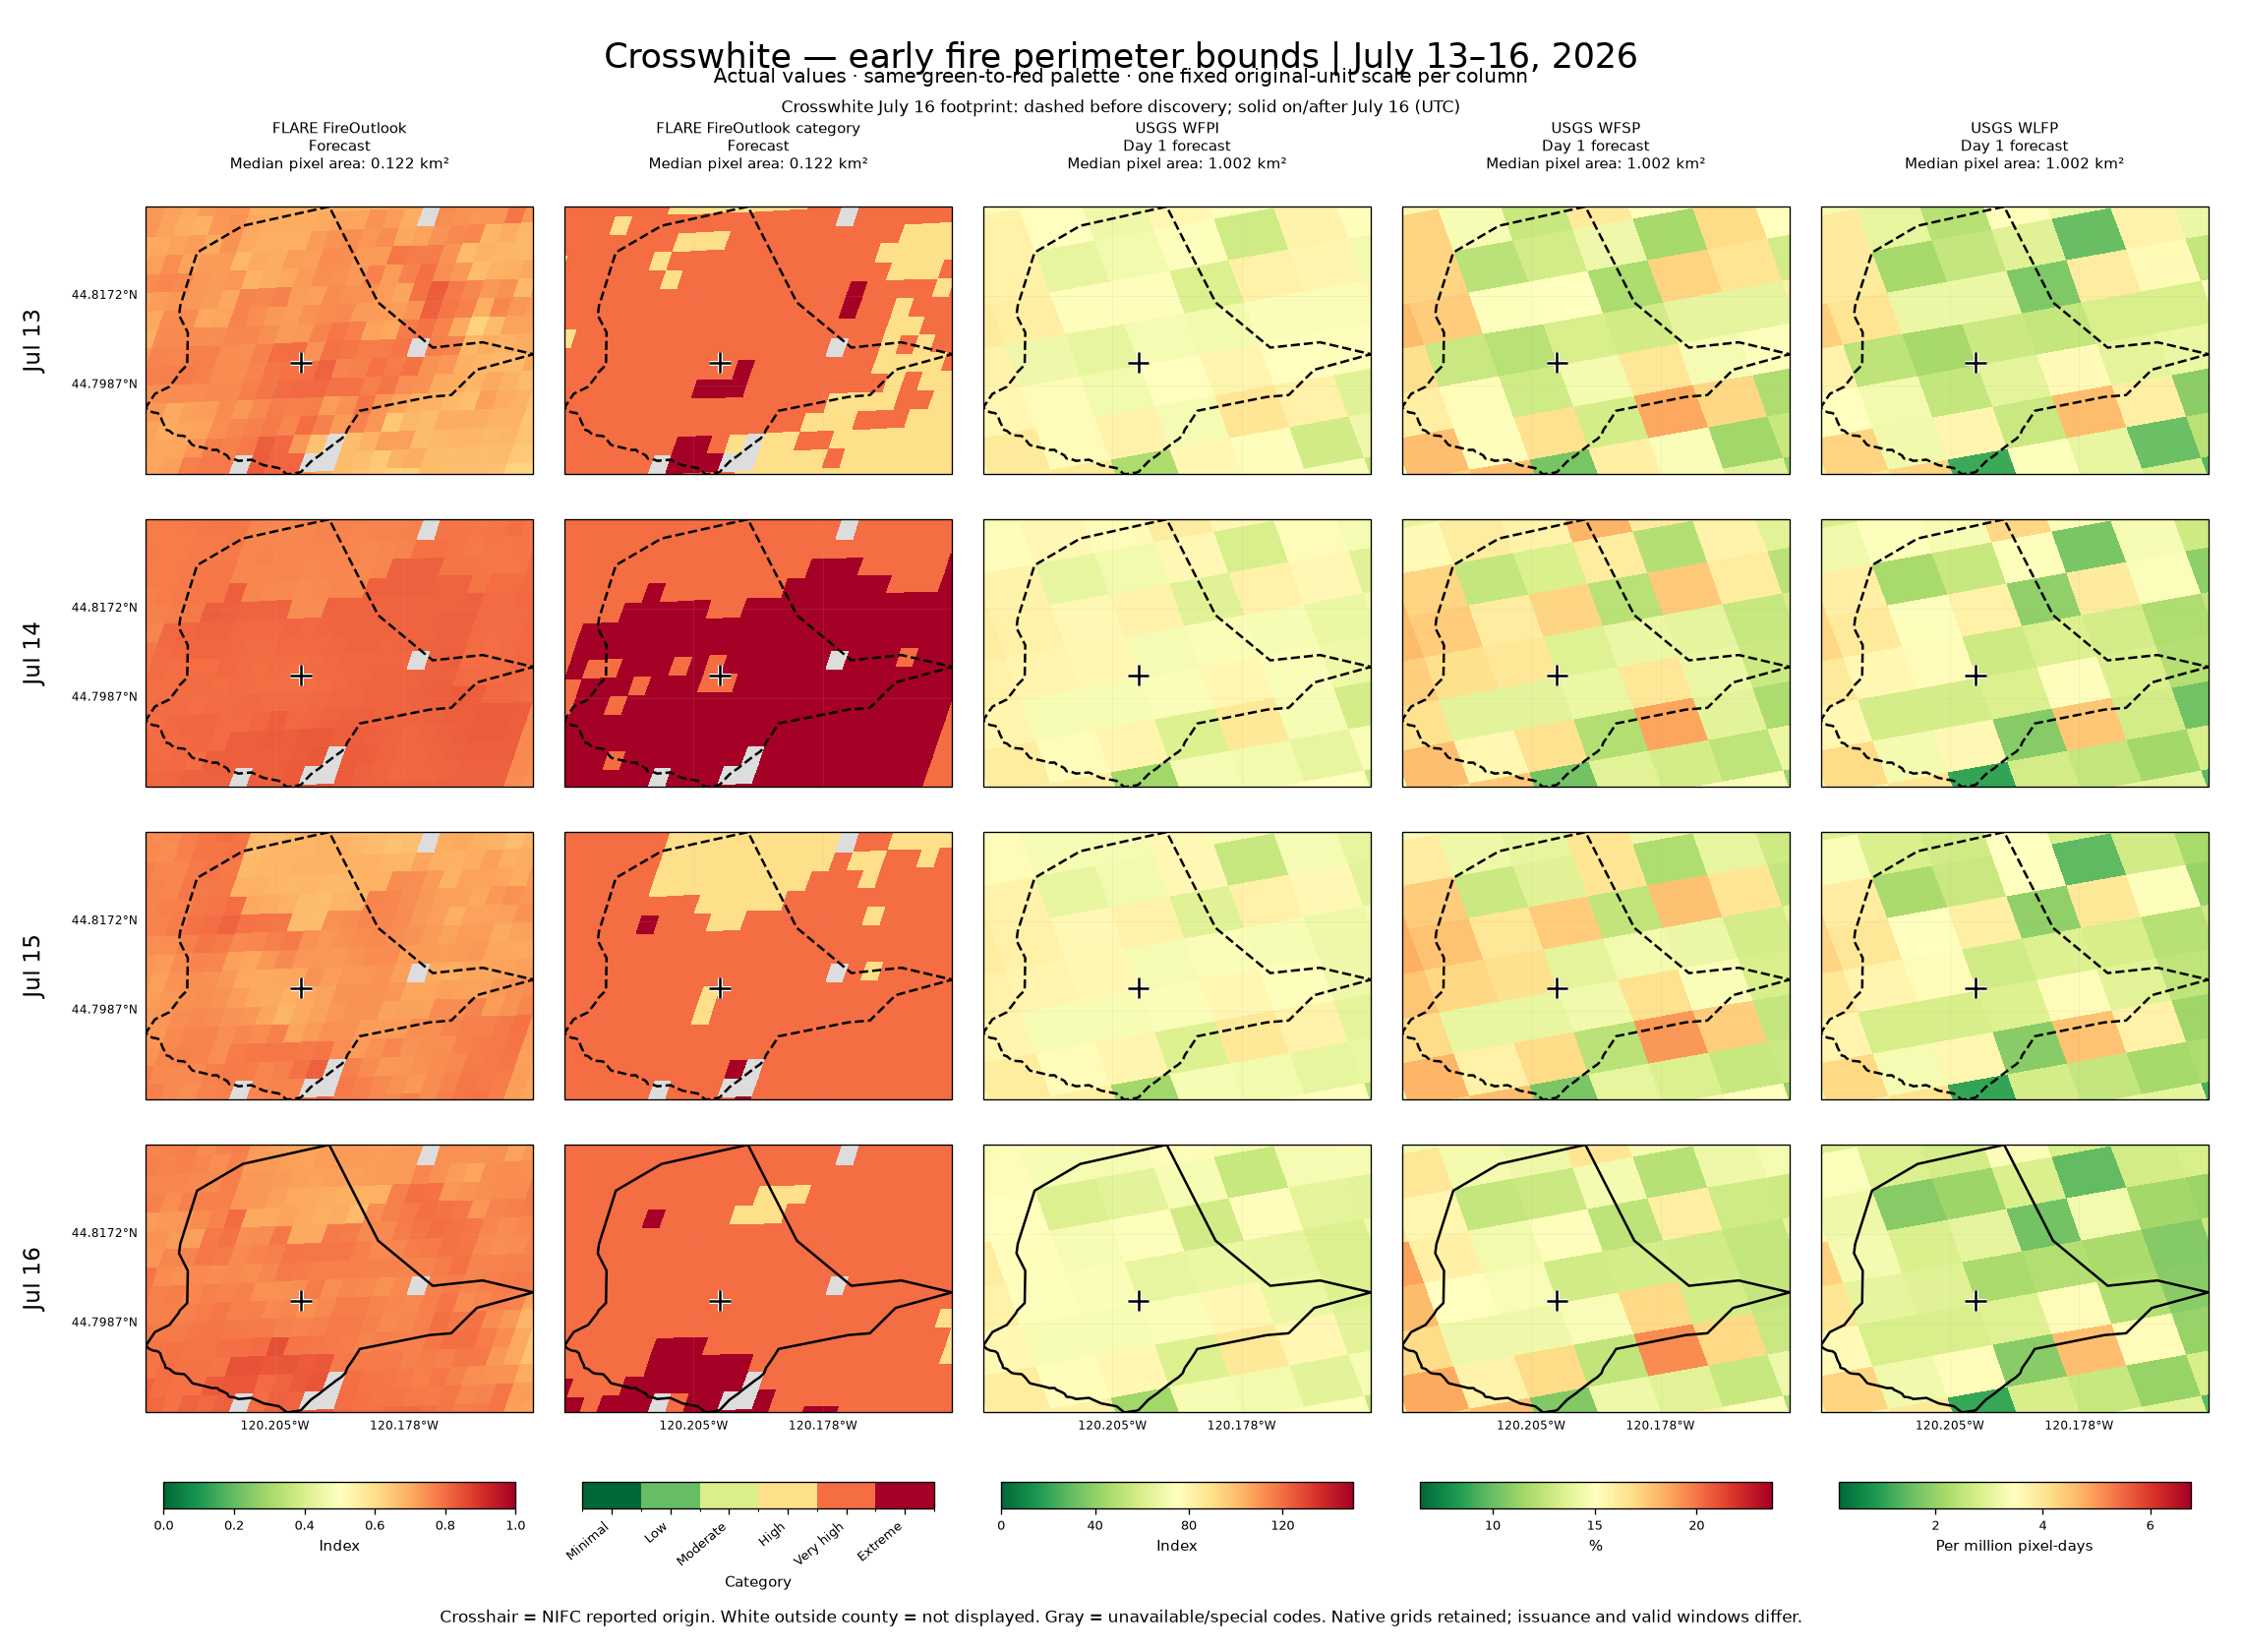

In [8]:
fc.matrix(comparison_county, numerical_data, flare_matrix, wider=True)